# Regression Modeling

This notebook loads the prepared modeling dataset generated during the data preparation stage and develops, tunes, and evaluates regression models for `Aggregate_Total_Rev`.

## Load Prepared Modeling Data

The cleaned modeling dataset generated in `01_regression_eda.ipynb` is loaded from the processed data directory.

In [53]:
import pandas as pd

model_df = pd.read_csv(
    "../data/processed/telecom_regression_model_data.csv"
)

print("Shape:", model_df.shape)
model_df.head()

Shape: (2000, 9)


,network_age,Aggregate_Data_Vol,Aggregate_Calls,Aggregate_complaint_count,aug_user_type,sep_user_type,aug_fav_a,sep_fav_a,Aggregate_Total_Rev
0,1914.0,1.161130e+01,375,1,2G,2G,telenor,mobilink,1592.7200
1,2073.0,2.531725e+03,389,1,2G,2G,mobilink,ufone,1404.1496
2,3139.0,2.913306e+04,15,1,Other,Other,ptcl,telenor,85.5504
3,139.0,2.674413e+05,636,2,2G,2G,telenor,ufone,2315.2292
4,139.0,1.461621e+06,17,1,NaN,NaN,mobilink,ufone,227.8620


In [20]:
print("Columns:")
print(model_df.columns.tolist())

print("\nMissing values:")
print(model_df.isnull().sum())

Columns:
['network_age', 'Aggregate_Data_Vol', 'Aggregate_Calls', 'Aggregate_complaint_count', 'aug_user_type', 'sep_user_type', 'aug_fav_a', 'sep_fav_a', 'Aggregate_Total_Rev']

Missing values:
network_age                    5
Aggregate_Data_Vol             0
Aggregate_Calls                0
Aggregate_complaint_count      0
aug_user_type                245
sep_user_type                206
aug_fav_a                     60
sep_fav_a                      1
Aggregate_Total_Rev            0
dtype: int64


#### Train/Test Split (modeling stage)

In [21]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns="Aggregate_Total_Rev")
y = model_df["Aggregate_Total_Rev"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1600, 8)
X_test: (400, 8)
y_train: (1600,)
y_test: (400,)


Create a baseline:\
very simple regression baseline: Predict the training-set mean revenue for every customer

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_prediction = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_prediction
)

print("Baseline Mean:", y_train.mean())
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R²:", baseline_r2)

Baseline Mean: 897.1680432625
Baseline MAE: 676.3777815709375
Baseline RMSE: 1473.1939839222505
Baseline R²: -0.0007107161539146034


The R² is essentially 0, which makes sense because the baseline simply predicts the training mean for everyone.\
The important point is:\
 Our actual regression model needs to improve substantially on this baseline.

#### Multiple Linear Regression
we'll use a proper scikit-learn Pipeline with ColumnTransformer.\
Numerical → Median imputation & Categorical → "Unknown" for missing → One-hot encoding → Linear Regression → Prediction


Define the columns

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

numeric_features = [
    "network_age",
    "Aggregate_Data_Vol",
    "Aggregate_Calls",
    "Aggregate_complaint_count"
]

categorical_features = [
    "aug_user_type",
    "sep_user_type",
    "aug_fav_a",
    "sep_fav_a"
]

Build preprocessing

In [24]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Build the Linear Regression pipeline

In [25]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

Train

In [26]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['network_age','Aggregate_Data_Vol','Aggregate_Calls',...,'sep_user_type', 'aug_fav_a','sep_fav_a']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

Predict

In [27]:
y_pred = linear_model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[1066.87277745 1005.18854111  461.65680162 1073.77890338  451.86476356
  443.79434286  432.26821747  547.15874071 1078.48702919  457.81849323]


Evaluate Linear Regression


In [28]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

Linear Regression
MAE : 511.31142173132105
MSE : 1814091.1908513242
RMSE: 1346.8820255877365
R²  : 0.1635349653960808


this is a clear improvement over the baseline, let's evaluate it against the baseline:
- MAE: 676.38 → 511.31 : verage absolute prediction error decreased by about 165.07 revenue units.
- RMSE: 1473.19 → 1346.88 : the model also reduced the impact of large prediction errors.
- R²: -0.0007 → 0.1635 : this is the most important conceptual improvement: the model explains about 16.35% of the variation in the test target, whereas the mean baseline essentially explained none.

model is learning useful relationships from the features.\
But notice something important RMSE is still much larger than MAE:\
MAE = 511 vs RMSE = 1347\
That's consistent with what we saw earlier: Aggregate_Total_Rev is strongly right-skewed, with a few very large revenue values. Those large errors are being penalized heavily by RMSE.

The model improves substantially over the mean baseline, but the large gap between MAE and RMSE suggests that some high-revenue customers generate relatively large prediction errors.

Residual Analysis (Residual = Actual − Predicted)

In [29]:
residuals = y_test - y_pred

print("Mean residual:", residuals.mean())
print("Min residual:", residuals.min())
print("Max residual:", residuals.max())

Mean residual: 11.614270760687791
Min residual: -2530.524567465861
Max residual: 22739.842268181143


A mean residual close to zero means the model is not strongly biased toward systematically overpredicting or underpredicting across the test set.\
11.6 is small relative to the revenue values, so this is reasonable.

A residual of +22,739.84 means there is at least one customer where: Actual revenue − Predicted revenue ≈ 22,740\
So the model severely underestimated at least one high-revenue customer (RMSE heavily penalizes those very large errors).

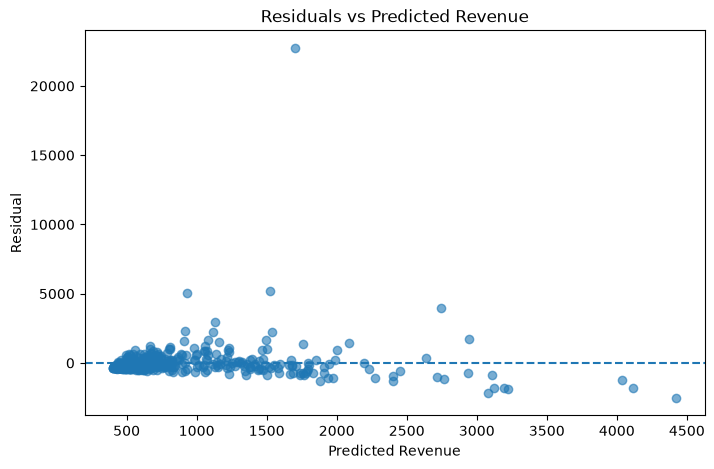

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Revenue")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Revenue")

plt.show()

What we can see:
1. Most residuals are clustered around zero
That's good. The model isn't making huge errors for the majority of customers.
2. There are several large positive residuals Especially the point around: predicted revenue ≈ 1,700 → residual ≈ 22,700\
That means the model dramatically underpredicted a high-revenue customer, This corresponds directly to the +22,739.84 maximum residual we calculated.
3. There are also large negative residuals at higher predictions At predicted revenues around 3,000–4,500, several residuals are negative.\
This suggests the model's errors aren't perfectly random across the prediction range.
4. The spread isn't constant, The residuals are much more concentrated near zero for lower predicted revenue, while the extreme observations produce much larger errors.\
This is evidence of heteroscedasticity (non-constant residual variance).

The residual plot shows that most predictions are centered around zero, but there are several extreme residuals, particularly for high-revenue observations. The spread of residuals is not completely constant, suggesting heteroscedasticity and indicating that ordinary linear regression may struggle with extreme revenue customers.

The purpose of residual analysis here is to understand the limitations of our baseline linear model.

#### Ridge Regression

In [31]:
from sklearn.linear_model import Ridge

numeric_transformer_ridge = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor_ridge = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_ridge, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ridge),
        ("regressor", Ridge(alpha=1.0))
    ]
)

In [32]:
ridge_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)

print(y_pred_ridge[:10])

[1198.14333719  789.86441673  398.75672578  997.13390169  260.66018882
  253.77037432  157.4831688   726.84370796  832.41150518   44.8433    ]


In [ ]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression")
print("MAE :", mae_ridge)
print("MSE :", mse_ridge)
print("RMSE:", rmse_ridge)
print("R²  :", r2_ridge)

Ridge Regression
MAE : 491.277131088907
MSE : 1705398.6795887204
RMSE: 1305.9091391014615
R²  : 0.21365233857608867


Ridge clearly improved over ordinary Linear Regression on this test set.\
Compared with Linear Regression:
- MAE: 511.31 → 491.28 ↓
- RMSE: 1346.88 → 1305.91 ↓
- R²: 0.1635 → 0.2137 ↑
So Ridge is currently giving us the better test-set metrics.\
The R² increase means the Ridge model explains about 21.4% of the variation in the test target, compared with about 16.4% for ordinary Linear Regression.

Ridge is useful because we have:\
- multiple numerical features
- several categorical variables
- one-hot encoded categories
- potentially correlated/overlapping predictors\
Ridge penalizes large coefficients, which can make the model more stable and improve generalization.

On this dataset, Ridge with α=1 produced lower MAE and RMSE and higher R² than ordinary Linear Regression. I would still validate the choice using cross-validation rather than relying on a single test split.

5-fold cross-validation on the training data to tune alpha (strength of regularization)\
GridSearchCV

In [34]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...r', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informa

See the best value

In [35]:
print("Best alpha:", ridge_grid.best_params_["regressor__alpha"])
print("Best CV RMSE:", -ridge_grid.best_score_)

Best alpha: 100
Best CV RMSE: 797.742432016634


among the six values we tested, 100 gave the lowest average cross-validation RMSE on the training data.\
CV RMSE (797.74) ≠ test RMSE (1305.91), They measure performance on different data:
- 797.74 → average validation performance across the 5 training folds
- 1305.91 → performance on our completely untouched test set

evaluate the tuned Ridge (alpha=100) on the untouched test set

In [36]:
y_pred_ridge_tuned = ridge_grid.predict(X_test)

In [37]:
mae_ridge_tuned = mean_absolute_error(y_test, y_pred_ridge_tuned)
mse_ridge_tuned = mean_squared_error(y_test, y_pred_ridge_tuned)
rmse_ridge_tuned = np.sqrt(mse_ridge_tuned)
r2_ridge_tuned = r2_score(y_test, y_pred_ridge_tuned)

print("Tuned Ridge Regression")
print("MAE :", mae_ridge_tuned)
print("MSE :", mse_ridge_tuned)
print("RMSE:", rmse_ridge_tuned)
print("R²  :", r2_ridge_tuned)

Tuned Ridge Regression
MAE : 487.1286733485515
MSE : 1739322.0947366208
RMSE: 1318.8336114675803
R²  : 0.19801048398318077


Interestingly, α=1 had a slightly better test RMSE and R², while α=100 had the lowest MAE.\
That's not a contradiction. GridSearchCV selected α=100 based on its average CV RMSE, not based on the final test-set metrics. The test set was not used to select the hyperparameter—which is exactly what we wanted.

I used 5-fold cross-validation to tune Ridge's alpha parameter. The best cross-validated value was α=100. I then evaluated that tuned model once on the untouched test set. It achieved an MAE of about 487, RMSE of about 1,319, and R² of about 0.198.

the model still has relatively large errors for extreme-revenue customers, which is consistent with the strong right-skewness and residual behavior we observed earlier.

#### Lasso Regression

In [38]:
from sklearn.linear_model import Lasso

numeric_transformer_lasso = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor_lasso = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_lasso, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

lasso_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_lasso),
        ("regressor", Lasso(alpha=1.0, max_iter=50000))
    ]
)

In [39]:
lasso_model.fit(X_train, y_train)

y_pred_lasso = lasso_model.predict(X_test)

In [40]:
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression")
print("MAE :", mae_lasso)
print("MSE :", mse_lasso)
print("RMSE:", rmse_lasso)
print("R²  :", r2_lasso)

Lasso Regression
MAE : 491.07340711115836
MSE : 1707380.2180888942
RMSE: 1306.6676004588521
R²  : 0.21273866473296776


Compared with ordinary Linear Regression, Lasso improved all three metrics.\
The interesting part is that Ridge and Lasso are extremely close on this dataset. the two regularization methods produced similar predictive performance here.

tune Lasso's alpha using cross-validation

In [41]:
param_grid_lasso = {
    "regressor__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

lasso_grid = GridSearchCV(
    estimator=lasso_model,
    param_grid=param_grid_lasso,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

print("Best alpha:", lasso_grid.best_params_["regressor__alpha"])
print("Best CV RMSE:", -lasso_grid.best_score_)

Best alpha: 10
Best CV RMSE: 798.7255518843037


evaluate the tuned Lasso on the untouched test set

In [42]:
y_pred_lasso_tuned = lasso_grid.predict(X_test)

mae_lasso_tuned = mean_absolute_error(y_test, y_pred_lasso_tuned)
mse_lasso_tuned = mean_squared_error(y_test, y_pred_lasso_tuned)
rmse_lasso_tuned = np.sqrt(mse_lasso_tuned)
r2_lasso_tuned = r2_score(y_test, y_pred_lasso_tuned)

print("Tuned Lasso Regression")
print("MAE :", mae_lasso_tuned)
print("MSE :", mse_lasso_tuned)
print("RMSE:", rmse_lasso_tuned)
print("R²  :", r2_lasso_tuned)

Tuned Lasso Regression
MAE : 489.54649209210254
MSE : 1747956.2361092865
RMSE: 1322.102959723367
R²  : 0.19402934047811105


| Model | Alpha | MAE | RMSE | R² |
|---|---:|---:|---:|---:|
| Ridge | 1 | 491.28 | **1305.91** | **0.2137** |
| Ridge (tuned) | **100** | **487.13** | 1318.83 | 0.1980 |
| Lasso | 1 | 491.07 | 1306.67 | 0.2127 |
| Lasso (tuned) | **10** | 489.55 | 1322.10 | 0.1940 |

I compared Ridge and Lasso using cross-validation for hyperparameter tuning. Ridge with α=100 had the best cross-validated RMSE among its candidates and slightly outperformed tuned Lasso on the final test set. Therefore, I selected Ridge as the better regularized model for this dataset.

GridSearchCV selected Ridge α=100 based on cross-validation. On the final test set, α=100 achieved the lowest MAE, while α=1 happened to achieve slightly better RMSE and R². We retain α=100 because α was selected without using the test set.

we've done:
1. Baseline
2. Linear Regression
3. Ridge α=1
4. Ridge tuned α=100
5. Lasso α=1
6. Lasso tuned α=10

Baseline → Linear Regression → Regularization → Tuning

final model comparison

In [43]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge (α=1)",
        "Ridge (Tuned)",
        "Lasso (α=1)",
        "Lasso (Tuned)"
    ],
    "MAE": [
        676.3778,
        511.3114,
        491.2771,
        487.1287,
        491.0734,
        489.5465
    ],
    "RMSE": [
        1473.1940,
        1346.8820,
        1305.9091,
        1318.8336,
        1306.6676,
        1322.1030
    ],
    "R²": [
        -0.0007,
        0.1635,
        0.2137,
        0.1980,
        0.2127,
        0.1940
    ]
})

model_comparison

,Model,MAE,RMSE,R²
0,Baseline,676.3778,1473.1940,-0.0007
1,Linear Regression,511.3114,1346.8820,0.1635
2,Ridge (α=1),491.2771,1305.9091,0.2137
3,Ridge (Tuned),487.1287,1318.8336,0.1980
4,Lasso (α=1),491.0734,1306.6676,0.2127
5,Lasso (Tuned),489.5465,1322.1030,0.1940


1. Regression clearly beats the baseline\
So the features contain meaningful predictive information
2. Regularization improved the model\
Both outperform ordinary Linear Regression.
3. Tuning didn't improve every test metric

##### Inspect the tuned Ridge coefficients

Because we used OneHotEncoder, we need to first recover the feature names after preprocessing.

In [44]:
# Get feature names after preprocessing
feature_names = ridge_grid.best_estimator_["preprocessor"].get_feature_names_out()

# Get Ridge coefficients
coefficients = ridge_grid.best_estimator_["regressor"].coef_

# Create a table
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient value
coefficient_df["Absolute_Coefficient"] = coefficient_df["Coefficient"].abs()

coefficient_df = coefficient_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

coefficient_df.head(20)

,Feature,Coefficient,Absolute_Coefficient
2,num__Aggregate_Calls,561.592014,561.592014
21,cat__sep_fav_a_ptcl,-178.466381,178.466381
24,cat__sep_fav_a_warid,170.028900,170.028900
5,cat__aug_user_type_3G,133.020335,133.020335
1,num__Aggregate_Data_Vol,129.852560,129.852560
12,cat__aug_fav_a_Unknown,85.338048,85.338048
6,cat__aug_user_type_Other,-65.698601,65.698601
10,cat__sep_user_type_Other,-65.698601,65.698601
14,cat__aug_fav_a_ptcl,-64.261282,64.261282
9,cat__sep_user_type_3G,64.194299,64.194299


1. Strongest numeric feature: Aggregate_Calls → +561.59\
Because we standardized the numeric features before Ridge, A one-standard-deviation increase in Aggregate_Calls is associated with an increase of about 562 units in predicted revenue, holding the other features constant (customers making more calls tend to generate more revenue).
2. Aggregate_Data_Vol → +129.85\
Also positive so customers with higher data usage tend to have higher predicted revenue, although its standardized effect is considerably smaller than calls.
3. network_age → +31.63\
Positive but relatively small compared with Aggregate_Calls, So network age contributes some predictive information, but it isn't the dominant predictor in this model.
4. Categorical features \
These coefficients represent the effect of those categories relative to the omitted/reference category created by one-hot encoding.\
ex: sep_fav_a_ptcl → -178.47\
Holding the other features constant, the model associates the sep_fav_a = ptcl category with a lower predicted revenue relative to the reference category.
5. A very important observation\
aug_user_type_3G  → +133.02\
sep_user_type_3G  → +64.19\
The model associates both 3G categories with higher predicted revenue relative to their respective reference categories.\
aug_user_type_2G → -34.92\
sep_user_type_2G → -37.10\
The 2G categories have negative coefficients relative to the reference categories.\
business interpretation: usage/network behavior is associated with customer revenue.

Because we used: StandardScaler() for the numeric variables, while the categorical variables were one-hot encoded, the coefficient magnitudes across numeric and categorical features aren't perfectly apples-to-apples.\
So we say: Aggregate_Calls has the largest coefficient magnitude in the fitted model, indicating a strong contribution to the model's predictions.

#### Final residual analysis for the selected Ridge model

Generate Ridge residuals

In [45]:
# Predictions from the selected Ridge model
y_pred_ridge_final = ridge_grid.predict(X_test)

# Residuals
ridge_residuals = y_test - y_pred_ridge_final

print("Mean residual:", ridge_residuals.mean())
print("Min residual:", ridge_residuals.min())
print("Max residual:", ridge_residuals.max())

Mean residual: 15.729857865179238
Min residual: -2402.9096737823475
Max residual: 22492.84856024793


1. Mean residual = 15.73: This is relatively close to zero compared with the scale of the target.
2. Minimum = -2,402.91: There are some customers for whom the model overpredicted revenue by around 2,400.
3. Maximum = 22,492.85: There is at least one customer whose actual revenue is approximately 22,493 higher than the model predicted.\
That is consistent with the extremely high target values we saw earlier.

Ridge model predicts the typical customers reasonably better than the baseline, but struggles to capture extreme high-revenue customers.\
That's also reflected in: MAE ≈ 487, RMSE ≈ 1,319, RMSE is substantially larger than MAE because the large errors are being heavily penalized.

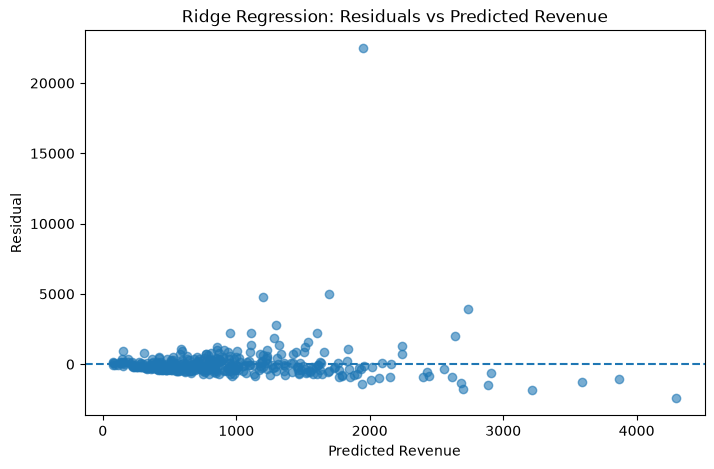

In [46]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_ridge_final,
    ridge_residuals,
    alpha=0.6
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Revenue")
plt.ylabel("Residual")
plt.title("Ridge Regression: Residuals vs Predicted Revenue")

plt.show()

1. Most residuals are close to zero\
That means the model is making reasonably close predictions for a large portion of customers.
2. The spread increases for larger predictions\
At lower predicted revenue, the residuals are relatively tightly clustered.\
As predicted revenue increases, the errors become more spread out.\
This suggests heteroscedasticity — the variance of the errors isn't constant across the prediction range.
3. There are several large residuals\
The most obvious point is around: Residual ≈ +22,500, Means the model severely underpredicted one high-revenue customer.\
There are also several negative residuals at higher predicted revenue, showing some cases where the model overpredicted.\
The Ridge model performs reasonably for typical customers but struggles with extreme/high-revenue customers, and the residual variance is not constant.

Because the target is extremely right-skewed, one natural question is:\
Would transforming the target with log1p help the model handle extreme revenue values better?

Create the log target

In [47]:
y_train_log = np.log1p(y_train)

Train Ridge on log1p(revenue)

In [48]:
log_ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ridge),
        ("regressor", Ridge(alpha=100))
    ]
)

# Train on log-transformed target
log_ridge_model.fit(X_train, y_train_log)

# Predict in log space
y_pred_log = log_ridge_model.predict(X_test)

# Convert predictions back to original revenue scale
y_pred_log_ridge = np.expm1(y_pred_log)

evaluate the log-Ridge model on the original revenue scale

In [49]:
mae_log_ridge = mean_absolute_error(y_test, y_pred_log_ridge)
mse_log_ridge = mean_squared_error(y_test, y_pred_log_ridge)
rmse_log_ridge = np.sqrt(mse_log_ridge)
r2_log_ridge = r2_score(y_test, y_pred_log_ridge)

print("Log-Target Ridge Regression")
print("MAE :", mae_log_ridge)
print("MSE :", mse_log_ridge)
print("RMSE:", rmse_log_ridge)
print("R²  :", r2_log_ridge)

Log-Target Ridge Regression
MAE : 557.6023439963687
MSE : 2413962.0516763907
RMSE: 1553.6930365025103
R²  : -0.11306138372264729


Log-Ridge vs our current Ridge

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Ridge α=100 | **487.13** | **1318.83** | **0.1980** |
| Log-Target Ridge α=100 | 557.60 | 1553.69 | **-0.1131** |

The log transformation made the model substantially worse on this test set.
- MAE increased by ~70
- RMSE increased by ~235
- R² went from 0.198 → -0.113\
negative R² means the log-target model performed worse than simply predicting the mean revenue on this test set.\
So we do not select the log-transformed model.

#### Final model diagnosis

Based on everything we tested:
1. Baseline\
The mean predictor gave:
- MAE: 676.38
- RMSE: 1473.19
- R²: -0.0007\
So our features clearly provide useful predictive information.
2. Linear Regression
- MAE: 511.31
- RMSE: 1346.88
- R²: 0.1635\
A substantial improvement over the baseline.
3. Regularization\
Ridge and Lasso both improved on ordinary Linear Regression.\
Ridge α=1:
- MAE: 491.28
- RMSE: 1305.91
- R²: 0.2137\
Lasso α=1:
- MAE: 491.07
- RMSE: 1306.67
- R²: 0.2127\
This tells us regularization was useful for this dataset.
4. Hyperparameter tuning\
Cross-validation selected:
- Ridge → α=100
- Lasso → α=10\
The tuned models performed similarly on the final test set, with tuned Ridge slightly better overall, But we correctly did not choose α based on the test set.
5. Residual analysis\
The final Ridge residual plot showed:
- Residuals generally centered around zero.
- Increasing spread at higher predictions.
- Several extreme residuals.
- One particularly large positive residual around 22,493.\
Therefore: The model struggles with extreme high-revenue customers and shows evidence of heteroscedasticity.

6. Log-target experiment\
We tested whether log1p(Aggregate_Total_Rev) would improve the situation.\
It did not:
- MAE: 557.60
- RMSE: 1553.69
- R²: -0.1131\
So we reject the log-target approach for this project.

#### final project metric to calculate
##### How much better is our selected Ridge model than the baseline in MAE?

In [50]:
mae_improvement = (
    (676.3777815709375 - 487.1286733485515)
    / 676.3777815709375
) * 100

print("MAE improvement over baseline:", mae_improvement, "%")

MAE improvement over baseline: 27.979793745270715 %


Compared with a mean baseline, my final Ridge model reduced MAE by approximately 28%, indicating that the telecom usage and customer characteristics provided meaningful predictive value for customer revenue.

Selected model: Ridge α=100, selected through 5-fold cross-validation.

Final test performance: MAE 487.13, RMSE 1318.83, R² 0.1980.

Best observed test RMSE/R² among our tested models: Ridge α=1, but α was not selected based on the test set.

#### Save the model

In [51]:
import joblib

final_model = ridge_grid.best_estimator_

joblib.dump(
    final_model,
    "../models/ridge_regression_alpha100.joblib"
)

print("Final model saved successfully.")

Final model saved successfully.
